# EDA on Biometric Data

In [5]:
# Importing libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [6]:
# Base paths (update if needed)
base_path = r"C:\\Users\\hp\\OneDrive\\Desktop\\UIDAI Data Hackathon 2026"
biometric_path = f"{base_path}/api_data_aadhar_biometric"

### Importing Demography-1 file

In [7]:
demo_1 = pd.read_csv(f"{biometric_path}/api_data_aadhar_biometric_0_500000.csv")
demo_1.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_
0,01-03-2025,Haryana,Mahendragarh,123029,280,577
1,01-03-2025,Bihar,Madhepura,852121,144,369
2,01-03-2025,Jammu and Kashmir,Punch,185101,643,1091
3,01-03-2025,Bihar,Bhojpur,802158,256,980
4,01-03-2025,Tamil Nadu,Madurai,625514,271,815


In [8]:
demo_1.shape

(500000, 6)

In [9]:
demo_1['state'].unique()

array(['Haryana', 'Bihar', 'Jammu and Kashmir', 'Tamil Nadu',
       'Maharashtra', 'Gujarat', 'Odisha', 'West Bengal', 'Kerala',
       'Rajasthan', 'Punjab', 'Himachal Pradesh', 'Uttar Pradesh',
       'Assam', 'Uttarakhand', 'Madhya Pradesh', 'Karnataka',
       'Andhra Pradesh', 'Telangana', 'Goa', 'Nagaland', 'Jharkhand',
       'Delhi', 'Chhattisgarh', 'Meghalaya', 'Chandigarh', 'Orissa',
       'Puducherry', 'Pondicherry', 'Manipur', 'Sikkim', 'Tripura',
       'Mizoram', 'Arunachal Pradesh', 'Ladakh',
       'Dadra and Nagar Haveli and Daman and Diu', 'Daman and Diu',
       'Andaman and Nicobar Islands', 'Andaman & Nicobar Islands',
       'Dadra and Nagar Haveli', 'Lakshadweep', 'Daman & Diu',
       'Dadra & Nagar Haveli', 'Jammu & Kashmir', 'WESTBENGAL',
       'andhra pradesh', 'Westbengal', 'West  Bengal', 'WEST BENGAL',
       'West Bangal', 'ODISHA', 'odisha', 'West bengal', 'west Bengal',
       'Uttaranchal', 'Chhatisgarh'], dtype=object)

In [11]:
demo_1['new_date'] = pd.to_datetime(
    demo_1['date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
).dt.strftime('%Y%m%d')

demo_1

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,01-03-2025,Haryana,Mahendragarh,123029,280,577,20250301
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301
2,01-03-2025,Jammu and Kashmir,Punch,185101,643,1091,20250301
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301
4,01-03-2025,Tamil Nadu,Madurai,625514,271,815,20250301
...,...,...,...,...,...,...,...
499995,19-09-2025,Delhi,West Delhi,110041,102,100,20250919
499996,19-09-2025,Delhi,West Delhi,110043,8,5,20250919
499997,19-09-2025,Delhi,West Delhi,110058,7,5,20250919
499998,19-09-2025,Goa,North Goa,403102,1,0,20250919


In [12]:
demo_1['new_date'].isnull().sum()

0

In [13]:
print(demo_1['new_date'].max())
print(demo_1['new_date'].min())


20250919
20250301


### Importing Demography-2 File

In [14]:
demo_2 = pd.read_csv(f"{biometric_path}/api_data_aadhar_biometric_500000_1000000.csv")
demo_2.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_
0,19-09-2025,Goa,North Goa,403502,0,4
1,19-09-2025,Goa,North Goa,403508,1,4
2,19-09-2025,Goa,North Goa,403513,2,0
3,19-09-2025,Goa,North Goa,403527,2,2
4,19-09-2025,Goa,South Goa,403601,7,3


In [15]:
demo_2.shape

(500000, 6)

In [16]:
demo_2['state'].unique()

array(['Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir',
       'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala',
       'Andaman & Nicobar Islands', 'Andaman and Nicobar Islands',
       'Andhra Pradesh', 'Mizoram', 'Nagaland', 'Odisha', 'Orissa',
       'Pondicherry', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim',
       'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh',
       'Uttarakhand', 'West Bengal', 'Ladakh', 'Lakshadweep',
       'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya',
       'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh',
       'Chhattisgarh', 'Dadra and Nagar Haveli', 'Daman & Diu', 'Delhi',
       'Daman and Diu', 'West  Bengal',
       'Dadra and Nagar Haveli and Daman and Diu', 'Dadra & Nagar Haveli',
       'West bengal', 'West Bangal', 'ODISHA', 'WEST BENGAL',
       'andhra pradesh', 'odisha', 'Westbengal', 'WESTBENGAL'],
      dtype=object)

In [17]:
demo_2['new_date']=pd.to_datetime(demo_2['date']).dt.strftime('%Y%m%d')
demo_2

C:\Users\hp\AppData\Local\Temp\ipykernel_18288\3808742326.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  demo_2['new_date']=pd.to_datetime(demo_2['date']).dt.strftime('%Y%m%d')


,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,19-09-2025,Goa,North Goa,403502,0,4,20250919
1,19-09-2025,Goa,North Goa,403508,1,4,20250919
2,19-09-2025,Goa,North Goa,403513,2,0,20250919
3,19-09-2025,Goa,North Goa,403527,2,2,20250919
4,19-09-2025,Goa,South Goa,403601,7,3,20250919
...,...,...,...,...,...,...,...
499995,07-11-2025,Kerala,Ernakulam,682020,1,6,20251107
499996,07-11-2025,Kerala,Ernakulam,682022,1,0,20251107
499997,07-11-2025,Kerala,Ernakulam,682023,0,1,20251107
499998,07-11-2025,Kerala,Ernakulam,682025,3,6,20251107


In [18]:
demo_2['new_date'].isnull().sum()

0

In [19]:
print(demo_2['new_date'].max())
print(demo_2['new_date'].min())


20251107
20250919


In [20]:
demo_2.dtypes

date            object
state           object
district        object
pincode          int64
bio_age_5_17     int64
bio_age_17_      int64
new_date        object
dtype: object

### Importing Demography-3 file

In [21]:
demo_3 = pd.read_csv(f"{biometric_path}/api_data_aadhar_biometric_1000000_1500000.csv")
demo_3.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_
0,07-11-2025,Haryana,Yamuna Nagar,135002,4,6
1,07-11-2025,Haryana,Yamunanagar,135001,1,2
2,07-11-2025,Himachal Pradesh,Bilaspur,174004,2,2
3,07-11-2025,Himachal Pradesh,Bilaspur,174005,1,0
4,07-11-2025,Himachal Pradesh,Bilaspur,174013,3,1


In [22]:
demo_3.shape

(500000, 6)

In [23]:
demo_3['state'].unique()

array(['Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand',
       'Karnataka', 'Kerala', 'Lakshadweep', 'Madhya Pradesh',
       'Maharashtra', 'Andaman & Nicobar Islands',
       'Andaman and Nicobar Islands', 'Andhra Pradesh',
       'Arunachal Pradesh', 'Assam', 'Bihar', 'Uttar Pradesh',
       'Uttarakhand', 'West Bengal', 'Chandigarh', 'Chhattisgarh',
       'Dadra & Nagar Haveli', 'Dadra and Nagar Haveli', 'Daman & Diu',
       'Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Jammu & Kashmir',
       'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Orissa',
       'Pondicherry', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim',
       'Tamil Nadu', 'Telangana', 'Tripura', 'Ladakh', 'West Bangal',
       'West bengal', 'odisha',
       'Dadra and Nagar Haveli and Daman and Diu', 'West  Bengal',
       'WEST BENGAL', 'andhra pradesh', 'Westbengal', 'Chhatisgarh',
       'ODISHA', 'WESTBENGAL', 'Uttaranchal'], dtype=object)

In [25]:
demo_3['new_date'] = pd.to_datetime(
    demo_3['date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
).dt.strftime('%Y%m%d')

demo_3

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,07-11-2025,Haryana,Yamuna Nagar,135002,4,6,20251107
1,07-11-2025,Haryana,Yamunanagar,135001,1,2,20251107
2,07-11-2025,Himachal Pradesh,Bilaspur,174004,2,2,20251107
3,07-11-2025,Himachal Pradesh,Bilaspur,174005,1,0,20251107
4,07-11-2025,Himachal Pradesh,Bilaspur,174013,3,1,20251107
...,...,...,...,...,...,...,...
499995,08-12-2025,Gujarat,Vadodara,391150,3,18,20251208
499996,08-12-2025,Gujarat,Vadodara,391168,11,34,20251208
499997,08-12-2025,Gujarat,Vadodara,391170,0,23,20251208
499998,08-12-2025,Gujarat,Vadodara,391410,9,4,20251208


In [26]:
demo_3['new_date'].isnull().sum()

0

In [27]:
print(demo_3['new_date'].max())
print(demo_3['new_date'].min())


20251208
20251107


### Importing Demography-4 data

In [28]:
demo_4 = pd.read_csv(f"{biometric_path}/api_data_aadhar_biometric_1500000_1861108.csv")
demo_4.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_
0,08-12-2025,Uttar Pradesh,Moradabad,244411,4,2
1,08-12-2025,Uttar Pradesh,Moradabad,244601,14,19
2,08-12-2025,Uttar Pradesh,Muzaffarnagar,251002,22,37
3,08-12-2025,Uttar Pradesh,Muzaffarnagar,251202,4,4
4,08-12-2025,Uttar Pradesh,Muzaffarnagar,251319,4,7


In [29]:
demo_4.shape

(361108, 6)

In [34]:
demo_4['new_date'] = pd.to_datetime(
    demo_4['date'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
).dt.strftime('%Y%m%d')

demo_4

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,08-12-2025,Uttar Pradesh,Moradabad,244411,4,2,20251208
1,08-12-2025,Uttar Pradesh,Moradabad,244601,14,19,20251208
2,08-12-2025,Uttar Pradesh,Muzaffarnagar,251002,22,37,20251208
3,08-12-2025,Uttar Pradesh,Muzaffarnagar,251202,4,4,20251208
4,08-12-2025,Uttar Pradesh,Muzaffarnagar,251319,4,7,20251208
...,...,...,...,...,...,...,...
361103,29-12-2025,West Bengal,Uttar Dinajpur,733201,4,9,20251229
361104,29-12-2025,West Bengal,Uttar Dinajpur,733213,0,1,20251229
361105,29-12-2025,West Bengal,West Midnapore,721304,0,3,20251229
361106,29-12-2025,West Bengal,West Midnapore,721451,2,0,20251229


In [35]:
print(demo_4['new_date'].max())
print(demo_4['new_date'].min())

20251229
20251208


### Merging three dataset 

In [36]:
#Merging all the files

df = pd.concat([demo_1, demo_2, demo_3, demo_4], axis=0, ignore_index=True)
df.shape


(1861108, 7)

In [37]:
df.head()

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
0,01-03-2025,Haryana,Mahendragarh,123029,280,577,20250301
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301
2,01-03-2025,Jammu and Kashmir,Punch,185101,643,1091,20250301
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301
4,01-03-2025,Tamil Nadu,Madurai,625514,271,815,20250301


In [38]:
# checking shape of data 
df.shape

(1861108, 7)

In [39]:
# checking null values in date
df['new_date'].isnull().sum()

0

In [40]:
# count unique value of state
df['state'].nunique()

57

In [41]:
df['state'].unique()

array(['Haryana', 'Bihar', 'Jammu and Kashmir', 'Tamil Nadu',
       'Maharashtra', 'Gujarat', 'Odisha', 'West Bengal', 'Kerala',
       'Rajasthan', 'Punjab', 'Himachal Pradesh', 'Uttar Pradesh',
       'Assam', 'Uttarakhand', 'Madhya Pradesh', 'Karnataka',
       'Andhra Pradesh', 'Telangana', 'Goa', 'Nagaland', 'Jharkhand',
       'Delhi', 'Chhattisgarh', 'Meghalaya', 'Chandigarh', 'Orissa',
       'Puducherry', 'Pondicherry', 'Manipur', 'Sikkim', 'Tripura',
       'Mizoram', 'Arunachal Pradesh', 'Ladakh',
       'Dadra and Nagar Haveli and Daman and Diu', 'Daman and Diu',
       'Andaman and Nicobar Islands', 'Andaman & Nicobar Islands',
       'Dadra and Nagar Haveli', 'Lakshadweep', 'Daman & Diu',
       'Dadra & Nagar Haveli', 'Jammu & Kashmir', 'WESTBENGAL',
       'andhra pradesh', 'Westbengal', 'West  Bengal', 'WEST BENGAL',
       'West Bangal', 'ODISHA', 'odisha', 'West bengal', 'west Bengal',
       'Uttaranchal', 'Chhatisgarh', 'Tamilnadu'], dtype=object)

# checking data consistency 

In [42]:
df[df['state']=='Uttaranchal']

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date
374898,13-09-2025,Uttaranchal,Almora,263601,0,1,20250913
1431510,05-12-2025,Uttaranchal,Garhwal,249302,0,1,20251205


## Mappind state with correct name 

In [43]:
df['state'] = df['state'].replace('Uttaranchal', 'Uttarakhand')


In [44]:
df['state'] = df['state'].replace('Tamilnadu', 'Tamil Nadu')


## Mapping the state name 

In [45]:
import pandas as pd
import re

def clean_state_name(x):
    if pd.isna(x):
        return x
    x = str(x).lower()
    x = re.sub(r'[^a-z\s]', ' ', x)   # remove symbols like &, .
    x = re.sub(r'\s+', ' ', x).strip()  # remove extra spaces
    return x


In [46]:
state_mapping = {
    # West Bengal
    'west bengal': 'West Bengal',
    'west bangal': 'West Bengal',
    'westbengal': 'West Bengal',
    'west  bengal': 'West Bengal',
    'westbengal ': 'West Bengal',
    'west bengli':  'West Bengal',
    

    # Andhra Pradesh
    'andhra pradesh': 'Andhra Pradesh',

    # Odisha
    'odisha': 'Odisha',
    'orissa': 'Odisha',

    # Jammu & Kashmir
    'jammu and kashmir': 'Jammu and Kashmir',
    'jammu kashmir': 'Jammu and Kashmir',

    # Collapse all Dadra / Daman variants into ONE state
    'dadra nagar haveli': 'Dadra and Nagar Haveli and Daman and Diu',
    'dadra and nagar haveli': 'Dadra and Nagar Haveli and Daman and Diu',
    'daman and diu': 'Dadra and Nagar Haveli and Daman and Diu',
    'dadra and nagar haveli and daman and diu': 'Dadra and Nagar Haveli and Daman and Diu',
    'the dadra and nagar haveli and daman and diu': 'Dadra and Nagar Haveli and Daman and Diu',
    'daman diu': 'Dadra and Nagar Haveli and Daman and Diu',


    # Puducherry
    'puducherry': 'Puducherry',


    # Andaman & Nicobar Islands
    'andaman and nicobar islands': 'Andaman and Nicobar Islands',
    'andaman nicobar islands': 'Andaman and Nicobar Islands',

    # Puducherry
    'pondicherry': 'Puducherry',

    # Case-normalized direct matches
    'delhi': 'Delhi',
    'ladakh': 'Ladakh',
    'goa': 'Goa',
    'sikkim': 'Sikkim',
    'assam': 'Assam',
    'bihar': 'Bihar',
    'punjab': 'Punjab',
    'kerala': 'Kerala',
    'haryana': 'Haryana',
    'gujarat': 'Gujarat',
    'tamil nadu': 'Tamil Nadu',
    'telangana': 'Telangana',
    'karnataka': 'Karnataka',
    'maharashtra': 'Maharashtra',
    'Nagpur': 'Maharashtra',
    'rajasthan': 'Rajasthan',
    'uttar pradesh': 'Uttar Pradesh',
    'madhya pradesh': 'Madhya Pradesh',
    'himachal pradesh': 'Himachal Pradesh',
    'arunachal pradesh': 'Arunachal Pradesh',
    'chhattisgarh': 'Chhattisgarh',
    'chhatisgarh' : 'Chhattisgarh',
    'jharkhand': 'Jharkhand',
    'manipur': 'Manipur',
    'meghalaya': 'Meghalaya',
    'mizoram': 'Mizoram',
    'nagaland': 'Nagaland',
    'tripura': 'Tripura',
    'uttarakhand': 'Uttarakhand',
    'lakshadweep': 'Lakshadweep',
    'chandigarh': 'Chandigarh'
}


In [47]:
df['state_clean'] = (
    df['state']
    .apply(clean_state_name)
    .map(state_mapping)
)


In [50]:
# Drop invalid entries like numeric junk
df = df[~df['state'].astype(str).str.isnumeric()]

# Optional: check unmapped states
unmapped = df[df['state_clean'].isna()]['state'].unique()
print("Unmapped values:", unmapped)


Unmapped values: []


In [51]:
df.tail(20)

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean
1861088,29-12-2025,West Bengal,South 24 Parganas,743375,2,3,20251229,West Bengal
1861089,29-12-2025,West Bengal,South 24 Parganas,743378,2,3,20251229,West Bengal
1861090,29-12-2025,West Bengal,South 24 Parganas,743384,2,0,20251229,West Bengal
1861091,29-12-2025,West Bengal,South 24 Parganas,743392,0,1,20251229,West Bengal
1861092,29-12-2025,West Bengal,South 24 Parganas,743502,9,5,20251229,West Bengal
1861093,29-12-2025,West Bengal,South Dinajpur,733126,0,4,20251229,West Bengal
1861094,29-12-2025,West Bengal,South Dinajpur,733140,0,1,20251229,West Bengal
1861095,29-12-2025,West Bengal,South Dinajpur,733145,0,1,20251229,West Bengal
1861096,29-12-2025,West Bengal,South Dinajpur,733153,1,0,20251229,West Bengal
1861097,29-12-2025,West Bengal,South Dinajpur,733155,1,1,20251229,West Bengal


In [52]:
df['state_clean'].unique()

array(['Haryana', 'Bihar', 'Jammu and Kashmir', 'Tamil Nadu',
       'Maharashtra', 'Gujarat', 'Odisha', 'West Bengal', 'Kerala',
       'Rajasthan', 'Punjab', 'Himachal Pradesh', 'Uttar Pradesh',
       'Assam', 'Uttarakhand', 'Madhya Pradesh', 'Karnataka',
       'Andhra Pradesh', 'Telangana', 'Goa', 'Nagaland', 'Jharkhand',
       'Delhi', 'Chhattisgarh', 'Meghalaya', 'Chandigarh', 'Puducherry',
       'Manipur', 'Sikkim', 'Tripura', 'Mizoram', 'Arunachal Pradesh',
       'Ladakh', 'Dadra and Nagar Haveli and Daman and Diu',
       'Andaman and Nicobar Islands', 'Lakshadweep'], dtype=object)

In [53]:
df['state_clean'].nunique()

36

In [54]:
#checking datatypes 
df.dtypes

date            object
state           object
district        object
pincode          int64
bio_age_5_17     int64
bio_age_17_      int64
new_date        object
state_clean     object
dtype: object

In [55]:
df

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean
0,01-03-2025,Haryana,Mahendragarh,123029,280,577,20250301,Haryana
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar
2,01-03-2025,Jammu and Kashmir,Punch,185101,643,1091,20250301,Jammu and Kashmir
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar
4,01-03-2025,Tamil Nadu,Madurai,625514,271,815,20250301,Tamil Nadu
...,...,...,...,...,...,...,...,...
1861103,29-12-2025,West Bengal,Uttar Dinajpur,733201,4,9,20251229,West Bengal
1861104,29-12-2025,West Bengal,Uttar Dinajpur,733213,0,1,20251229,West Bengal
1861105,29-12-2025,West Bengal,West Midnapore,721304,0,3,20251229,West Bengal
1861106,29-12-2025,West Bengal,West Midnapore,721451,2,0,20251229,West Bengal


## Filtering data on state (Bihar)

In [56]:
df_bihar=df[df['state_clean']=='Bihar']
df_bihar

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar
15,01-03-2025,Bihar,Vaishali,844504,426,958,20250301,Bihar
56,01-03-2025,Bihar,Bhojpur,802164,165,311,20250301,Bihar
72,01-03-2025,Bihar,Darbhanga,846003,438,859,20250301,Bihar
...,...,...,...,...,...,...,...,...
1857239,29-12-2025,Bihar,Vaishali,844131,1,3,20251229,Bihar
1857240,29-12-2025,Bihar,Vaishali,844134,2,3,20251229,Bihar
1857241,29-12-2025,Bihar,Vaishali,844502,12,8,20251229,Bihar
1857242,29-12-2025,Bihar,West Champaran,845101,42,32,20251229,Bihar


In [57]:
df_bihar['district'].unique()

array(['Madhepura', 'Bhojpur', 'Vaishali', 'Darbhanga', 'Saharsa',
       'Katihar', 'Patna', 'Supaul', 'Begusarai', 'Banka', 'Bhagalpur',
       'Saran', 'Jehanabad', 'Muzaffarpur', 'West Champaran', 'Rohtas',
       'Jamui', 'Gopalganj', 'Nalanda', 'Samastipur', 'Araria', 'Siwan',
       'Aurangabad', 'Khagaria', 'Gaya', 'Purnia', 'Madhubani',
       'Sheikhpura', 'Buxar', 'Purnea', 'Munger', 'East Champaran',
       'Sitamarhi', 'Lakhisarai', 'Nawada', 'Kishanganj', 'Sheohar',
       'Arwal', 'Kaimur (Bhabua)', 'Pashchim Champaran', 'Aurangabad(bh)',
       'Monghyr', 'Samstipur', 'Sheikpura', 'Purba Champaran', 'Bhabua',
       'Aurangabad(BH)'], dtype=object)

In [58]:
# df_bihar['district'] = df_bihar['district'].replace('Near University Thana', 'Darbhanga')


In [59]:
import re
import pandas as pd

def clean_name(x):
    if pd.isna(x):
        return x
    x = str(x).lower()
    x = re.sub(r'[^a-z\s]', ' ', x)   # remove (), ., etc
    x = re.sub(r'\s+', ' ', x).strip()
    return x


In [60]:
district_mapping_bihar = {

    # Champaran
    'purbi champaran': 'East Champaran',
    'purba champaran': 'East Champaran',
    'east champaran': 'East Champaran',

    'pashchim champaran': 'West Champaran',
    'west champaran': 'West Champaran',

    # Aurangabad
    'aurangabad bh': 'Aurangabad',
    'aurangabad bh ': 'Aurangabad',
    'aurangabad': 'Aurangabad',

    # Purnia
    'purnia': 'Purnia',
    'purnea': 'Purnia',

    # Kaimur
    'kaimur bhabua': 'Kaimur',
    'bhabua': 'Kaimur',

    # Munger
    'munger': 'Munger',
    'monghyr': 'Munger',

    # Samastipur
    'samastipur': 'Samastipur',
    'samstipur': 'Samastipur',

    # Sheikhpura
    'sheikhpura': 'Sheikhpura',
    'sheikpura': 'Sheikhpura',
    'monghyr' : 'Munger',

    # Normalized direct matches
    'sitamarhi': 'Sitamarhi',
    'madhubani': 'Madhubani',
    'bhagalpur': 'Bhagalpur',
    'patna': 'Patna',
    'muzaffarpur': 'Muzaffarpur',
    'gaya': 'Gaya',
    'saran': 'Saran',
    'vaishali': 'Vaishali',
    'jehanabad': 'Jehanabad',
    'jamui': 'Jamui',
    'gopalganj': 'Gopalganj',
    'saharsa': 'Saharsa',
    'arwal': 'Arwal',
    'katihar': 'Katihar',
    'siwan': 'Siwan',
    'lakhisarai': 'Lakhisarai',
    'banka': 'Banka',
    'nalanda': 'Nalanda',
    'araria': 'Araria',
    'darbhanga': 'Darbhanga',
    'nawada': 'Nawada',
    'begusarai': 'Begusarai',
    'bhojpur': 'Bhojpur',
    'buxar': 'Buxar',
    'khagaria': 'Khagaria',
    'kishanganj': 'Kishanganj',
    'madhepura': 'Madhepura',
    'rohtas': 'Rohtas',
    'sheohar': 'Sheohar',
    'supaul': 'Supaul'
}


In [61]:
df_bihar['district_clean'] = (
    df_bihar['district']
    .apply(clean_name)
    .map(district_mapping_bihar)
    .fillna(df_bihar['district'])
)


C:\Users\hp\AppData\Local\Temp\ipykernel_18288\828442334.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_bihar['district_clean'] = (


In [62]:
# Remaining unmapped
df_bihar[df_bihar['district_clean'].isna()]['district'].unique()

# Count check
df_bihar['district_clean'].nunique()


38

In [63]:
df_bihar

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar,Madhepura
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar,Bhojpur
15,01-03-2025,Bihar,Vaishali,844504,426,958,20250301,Bihar,Vaishali
56,01-03-2025,Bihar,Bhojpur,802164,165,311,20250301,Bihar,Bhojpur
72,01-03-2025,Bihar,Darbhanga,846003,438,859,20250301,Bihar,Darbhanga
...,...,...,...,...,...,...,...,...,...
1857239,29-12-2025,Bihar,Vaishali,844131,1,3,20251229,Bihar,Vaishali
1857240,29-12-2025,Bihar,Vaishali,844134,2,3,20251229,Bihar,Vaishali
1857241,29-12-2025,Bihar,Vaishali,844502,12,8,20251229,Bihar,Vaishali
1857242,29-12-2025,Bihar,West Champaran,845101,42,32,20251229,Bihar,West Champaran


In [64]:
df_bihar['district_clean'].unique()

array(['Madhepura', 'Bhojpur', 'Vaishali', 'Darbhanga', 'Saharsa',
       'Katihar', 'Patna', 'Supaul', 'Begusarai', 'Banka', 'Bhagalpur',
       'Saran', 'Jehanabad', 'Muzaffarpur', 'West Champaran', 'Rohtas',
       'Jamui', 'Gopalganj', 'Nalanda', 'Samastipur', 'Araria', 'Siwan',
       'Aurangabad', 'Khagaria', 'Gaya', 'Purnia', 'Madhubani',
       'Sheikhpura', 'Buxar', 'Munger', 'East Champaran', 'Sitamarhi',
       'Lakhisarai', 'Nawada', 'Kishanganj', 'Sheohar', 'Arwal', 'Kaimur'],
      dtype=object)

In [65]:
df_bihar['new_date'].isnull().sum()

0

In [66]:
df_bihar['district_clean'].isnull().sum()

0

In [67]:
df_bihar['pincode'].nunique()

917

In [68]:
# df_bihar[['district_clean','pincode']].value_counts().reset_index(name='count')

In [69]:
pincode_check=df_bihar.groupby('district_clean')['pincode'].nunique().reset_index(name='unique_pincode_count')

In [70]:
df_bihar[df_bihar['district_clean']=='Kaimur']['pincode'].unique()

array([821106, 821112, 821105, 821102, 821103, 821104, 802132, 821108,
       821110, 821101, 821109, 821304, 802212, 802215, 821113, 821107,
       802213, 821312, 802218, 821310], dtype=int64)

In [71]:
pin_district_count = (
    df_bihar.groupby('pincode')['district_clean']
      .nunique()
      .reset_index(name='district_count')
)


In [72]:
pin_district_count

,pincode,district_count
0,431010,1
1,800001,1
2,800002,1
3,800003,1
4,800004,1
...,...,...
912,855114,1
913,855115,2
914,855116,1
915,855117,2


In [73]:
problem_pins = pin_district_count[
    pin_district_count['district_count'] > 1
]


In [74]:
problem_pins

,pincode,district_count
45,801304,2
46,801305,2
58,802112,2
72,802128,2
73,802129,2
...,...,...
905,855101,4
907,855105,2
909,855107,3
913,855115,2


In [78]:
df_flagged = df_bihar.merge(
    problem_pins[['pincode']],
    on='pincode',
    how='inner'
)


In [86]:
df_flagged

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean
0,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar,Madhepura
1,01-03-2025,Bihar,Saharsa,852210,58,118,20250301,Bihar,Saharsa
2,01-03-2025,Bihar,Katihar,855105,684,838,20250301,Bihar,Katihar
3,01-03-2025,Bihar,Supaul,852123,43,87,20250301,Bihar,Supaul
4,01-03-2025,Bihar,Darbhanga,847306,330,381,20250301,Bihar,Darbhanga
...,...,...,...,...,...,...,...,...,...
26679,29-12-2025,Bihar,Sitamarhi,843328,24,28,20251229,Bihar,Sitamarhi
26680,29-12-2025,Bihar,Sitamarhi,843334,0,1,20251229,Bihar,Sitamarhi
26681,29-12-2025,Bihar,Siwan,841427,4,0,20251229,Bihar,Siwan
26682,29-12-2025,Bihar,Siwan,841436,5,8,20251229,Bihar,Siwan


In [94]:
flagged_pincode_dominant=df_flagged.groupby(['district_clean', 'pincode'])[['bio_age_5_17','bio_age_17_']].sum().reset_index()
flagged_pincode_dominant.to_excel('flagged_pincode_dominant_bio.xlsx')


In [95]:
flagged_pincode_dominant['total_enroll']=flagged_pincode_dominant['bio_age_5_17']+flagged_pincode_dominant['bio_age_17_']
flagged_pincode_dominant.sort_values('pincode')

,district_clean,pincode,bio_age_5_17,bio_age_17_,total_enroll
260,Nalanda,801304,1055,1214,2269
284,Patna,801304,586,611,1197
261,Nalanda,801305,1292,1381,2673
285,Patna,801305,676,709,1385
82,Buxar,802112,1033,1151,2184
...,...,...,...,...,...
323,Purnia,855107,2075,2798,4873
324,Purnia,855115,1540,2099,3639
196,Kishanganj,855115,6712,8350,15062
185,Katihar,855117,2,12,14


In [96]:
idx = flagged_pincode_dominant.groupby('pincode')['total_enroll'].idxmax()
df_filtered = flagged_pincode_dominant.loc[idx]
df_filtered


,district_clean,pincode,bio_age_5_17,bio_age_17_,total_enroll
260,Nalanda,801304,1055,1214,2269
261,Nalanda,801305,1292,1381,2673
82,Buxar,802112,1033,1151,2184
83,Buxar,802128,1353,1727,3080
84,Buxar,802129,1270,1880,3150
...,...,...,...,...,...
194,Kishanganj,855101,14846,21651,36497
184,Katihar,855105,3919,5366,9285
195,Kishanganj,855107,12833,19060,31893
196,Kishanganj,855115,6712,8350,15062


In [99]:
df_bihar.loc[:, 'pin_multi_district_flag'] = (
    df_bihar
        .groupby('pincode')['district']
        .transform('nunique')
        .gt(1)
)


In [104]:
df_bihar['pin_multi_district_flag'] = ( df_bihar.groupby('pincode')['district'] .transform('nunique') > 1 )

In [105]:
pin_district_map

,pincode,district_clean
0,801304,"[Patna, Nalanda]"
1,801305,"[Nalanda, Patna]"
2,802112,"[Bhojpur, Buxar]"
3,802128,"[Buxar, Bhojpur]"
4,802129,"[Buxar, Bhojpur]"
...,...,...
305,855105,"[Katihar, Purnia]"
306,855107,"[Kishanganj, Purnia, Araria]"
307,855115,"[Kishanganj, Purnia]"
308,855117,"[Kishanganj, Katihar]"


In [106]:
file_path='pin_district_bio_map.xlsx'
#pin_district_map.to_excel(file_path, index=False)

In [107]:
df_bihar['pin_multi_district_flag'].value_counts()


pin_multi_district_flag
False    46675
True     36723
Name: count, dtype: int64

In [108]:
df_bihar['total_enroll']=df_bihar['bio_age_5_17']+df_bihar['bio_age_17_']
df_bihar

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean,pin_multi_district_flag,total_enroll
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar,Madhepura,True,513
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar,Bhojpur,False,1236
15,01-03-2025,Bihar,Vaishali,844504,426,958,20250301,Bihar,Vaishali,False,1384
56,01-03-2025,Bihar,Bhojpur,802164,165,311,20250301,Bihar,Bhojpur,False,476
72,01-03-2025,Bihar,Darbhanga,846003,438,859,20250301,Bihar,Darbhanga,False,1297
...,...,...,...,...,...,...,...,...,...,...,...
1857239,29-12-2025,Bihar,Vaishali,844131,1,3,20251229,Bihar,Vaishali,False,4
1857240,29-12-2025,Bihar,Vaishali,844134,2,3,20251229,Bihar,Vaishali,False,5
1857241,29-12-2025,Bihar,Vaishali,844502,12,8,20251229,Bihar,Vaishali,False,20
1857242,29-12-2025,Bihar,West Champaran,845101,42,32,20251229,Bihar,West Champaran,True,74


In [109]:
df_bihar['month']=df_bihar['new_date'].astype(str).str[4:6]
df_bihar

,date,state,district,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean,pin_multi_district_flag,total_enroll,month
1,01-03-2025,Bihar,Madhepura,852121,144,369,20250301,Bihar,Madhepura,True,513,03
3,01-03-2025,Bihar,Bhojpur,802158,256,980,20250301,Bihar,Bhojpur,False,1236,03
15,01-03-2025,Bihar,Vaishali,844504,426,958,20250301,Bihar,Vaishali,False,1384,03
56,01-03-2025,Bihar,Bhojpur,802164,165,311,20250301,Bihar,Bhojpur,False,476,03
72,01-03-2025,Bihar,Darbhanga,846003,438,859,20250301,Bihar,Darbhanga,False,1297,03
...,...,...,...,...,...,...,...,...,...,...,...,...
1857239,29-12-2025,Bihar,Vaishali,844131,1,3,20251229,Bihar,Vaishali,False,4,12
1857240,29-12-2025,Bihar,Vaishali,844134,2,3,20251229,Bihar,Vaishali,False,5,12
1857241,29-12-2025,Bihar,Vaishali,844502,12,8,20251229,Bihar,Vaishali,False,20,12
1857242,29-12-2025,Bihar,West Champaran,845101,42,32,20251229,Bihar,West Champaran,True,74,12


In [110]:
df_bihar_cleaned=df_bihar.drop(columns=['date','district','state'], axis=1)
df_bihar_cleaned

,pincode,bio_age_5_17,bio_age_17_,new_date,state_clean,district_clean,pin_multi_district_flag,total_enroll,month
1,852121,144,369,20250301,Bihar,Madhepura,True,513,03
3,802158,256,980,20250301,Bihar,Bhojpur,False,1236,03
15,844504,426,958,20250301,Bihar,Vaishali,False,1384,03
56,802164,165,311,20250301,Bihar,Bhojpur,False,476,03
72,846003,438,859,20250301,Bihar,Darbhanga,False,1297,03
...,...,...,...,...,...,...,...,...,...
1857239,844131,1,3,20251229,Bihar,Vaishali,False,4,12
1857240,844134,2,3,20251229,Bihar,Vaishali,False,5,12
1857241,844502,12,8,20251229,Bihar,Vaishali,False,20,12
1857242,845101,42,32,20251229,Bihar,West Champaran,True,74,12


In [111]:
df_bihar_dist_level=df_bihar_cleaned.groupby('district_clean')[['bio_age_5_17','bio_age_17_','total_enroll']].sum()
df_bihar_dist_level.shape

(38, 3)

In [112]:
df_bihar_dist_level

,bio_age_5_17,bio_age_17_,total_enroll
district_clean,,,
Araria,72533,82911,155444
Arwal,12094,18610,30704
Aurangabad,46591,50071,96662
Banka,49854,48373,98227
Begusarai,72549,74659,147208
Bhagalpur,72409,75905,148314
Bhojpur,39485,57511,96996
Buxar,24831,32197,57028
Darbhanga,93323,117057,210380


In [113]:
df_bihar_dist_level=df_bihar_dist_level.sort_values('total_enroll', ascending=False).reset_index()
#df_bihar_dist_level.to_excel("df_bihar_dist_bio_level.xlsx")


In [114]:
df_bihar_dist_level1=df_bihar_dist_level.head(10)
df_bihar_dist_level1

,district_clean,bio_age_5_17,bio_age_17_,total_enroll
0,Madhubani,110514,127621,238135
1,Purnia,107060,126445,233505
2,Katihar,98243,119037,217280
3,East Champaran,95962,116436,212398
4,Darbhanga,93323,117057,210380
5,Patna,93322,115692,209014
6,Muzaffarpur,93075,115469,208544
7,Samastipur,93174,107186,200360
8,Gaya,85898,99274,185172
9,Sitamarhi,84925,97075,182000


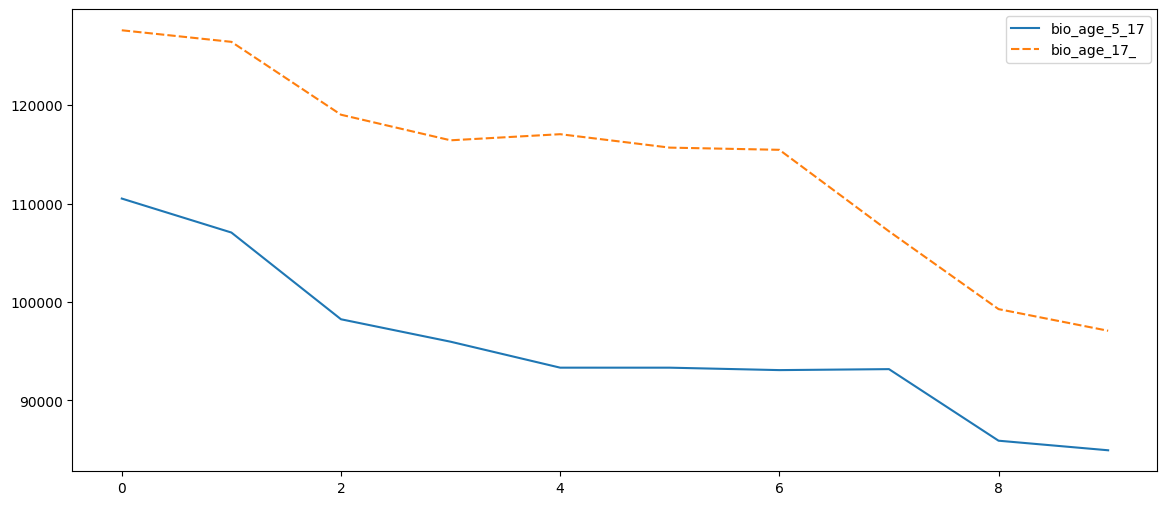

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))   # width, height in inches
sns.lineplot(data=df_bihar_dist_level1[['bio_age_5_17','bio_age_17_']])
plt.show()

In [116]:
df_bihar_pincode_level=df_bihar_cleaned.groupby('pincode')[['bio_age_5_17','bio_age_17_','total_enroll']].sum()
df_bihar_pincode_level.shape

(917, 3)

In [117]:
df_bihar_pincode_level.sort_values('total_enroll', ascending=False).reset_index()
#df_bihar_pincode_level.to_excel("df_bihar_pincode_bio_level.xlsx") 

,pincode,bio_age_5_17,bio_age_17_,total_enroll
0,855107,14909,21868,36777
1,855101,14848,21663,36511
2,854315,17230,17858,35088
3,854317,16548,18513,35061
4,855113,12906,13544,26450
...,...,...,...,...
912,824213,0,1,1
913,801111,1,0,1
914,843152,1,0,1
915,800029,1,0,1


In [118]:
df_bihar_pincode_level=df_bihar_pincode_level.sort_values('total_enroll', ascending=False).reset_index()

In [119]:
df_bihar_pincode_level1=df_bihar_pincode_level.head(10)
df_bihar_pincode_level1

,pincode,bio_age_5_17,bio_age_17_,total_enroll
0,855107,14909,21868,36777
1,855101,14848,21663,36511
2,854315,17230,17858,35088
3,854317,16548,18513,35061
4,855113,12906,13544,26450
5,854304,9954,14151,24105
6,854318,10404,13586,23990
7,854311,12658,11238,23896
8,843302,10976,12393,23369
9,855108,7773,14750,22523


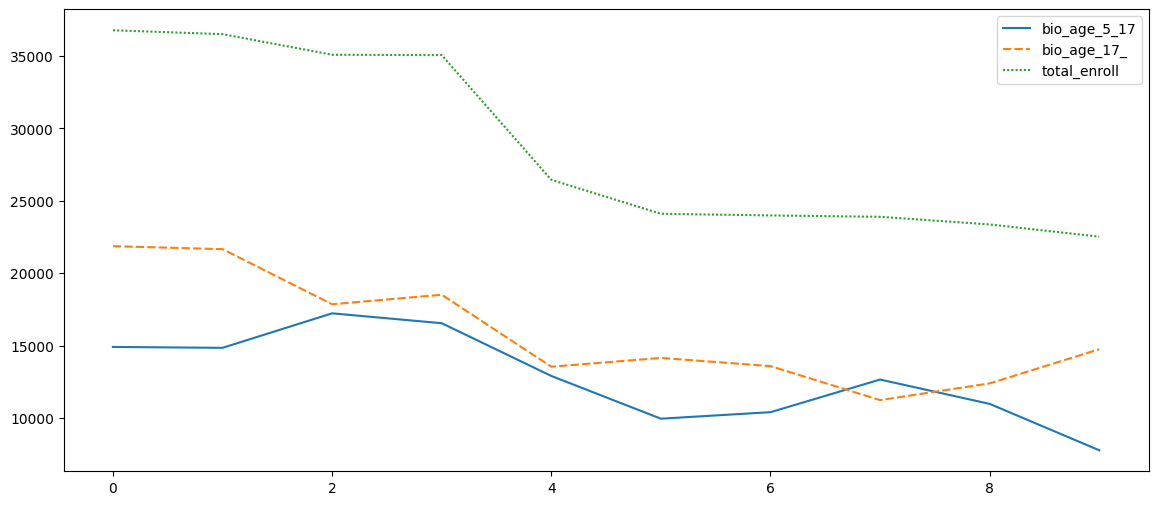

In [120]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))   # width, height in inches
sns.lineplot(data=df_bihar_pincode_level1[['bio_age_5_17','bio_age_17_','total_enroll']])
plt.show()

In [121]:
bihar_month_enroll_trend=df_bihar_cleaned.groupby('month')[['bio_age_5_17','bio_age_17_','total_enroll']].sum()
bihar_month_enroll_trend

,bio_age_5_17,bio_age_17_,total_enroll
month,,,
03,324179,439330,763509
04,419994,375725,795719
05,283915,268284,552199
06,239119,255338,494457
07,253037,351024,604061
09,145416,226685,372101
10,109493,160656,270149
11,151867,253099,404966
12,281121,359305,640426


In [122]:
#bihar_month_enroll_trend.to_excel("df_bihar_month_bio_level.xlsx") 

<Axes: xlabel='month'>

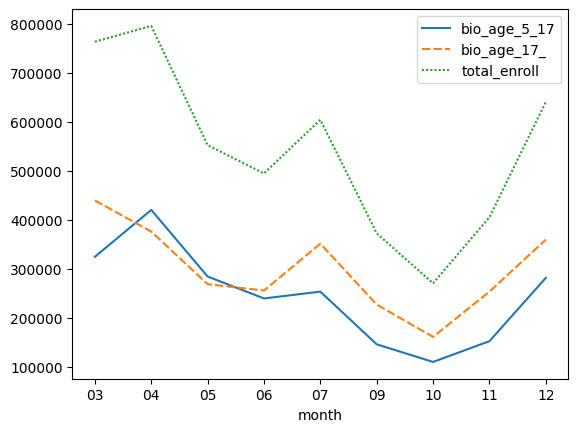

In [123]:
sns.lineplot(data=bihar_month_enroll_trend)

## Problem Statement & Approach
Analyze biometric authentication patterns to understand temporal trends, geographic hotspots, age-group distribution, and anomalies. The approach uses standardized cleaning, temporal aggregation, and multi-chart visualization.

## Datasets Used (Biometric)
Columns used: `state`, `district`, `date`, `pincode`, `bio_age_5_17`, `bio_age_17_`.

## Methodology (Summary)
- Standardized state/district names
- Parsed dates and created `month`, `year_month`
- Derived `total_biometric`
- Aggregated by state and month

## Key Findings (Aligned to Observations)
- **Temporal Trends**: Peaks align with enrollment drives and policy initiatives.
- **Geographic Patterns**: Urbanized and migration-heavy states show consistent activity.
- **Demographic Insights**: Higher activity in working-age population proxy (`bio_age_17_`).
- **Anomalies**: Districts with unusually high biometric updates may indicate center saturation or mobility.

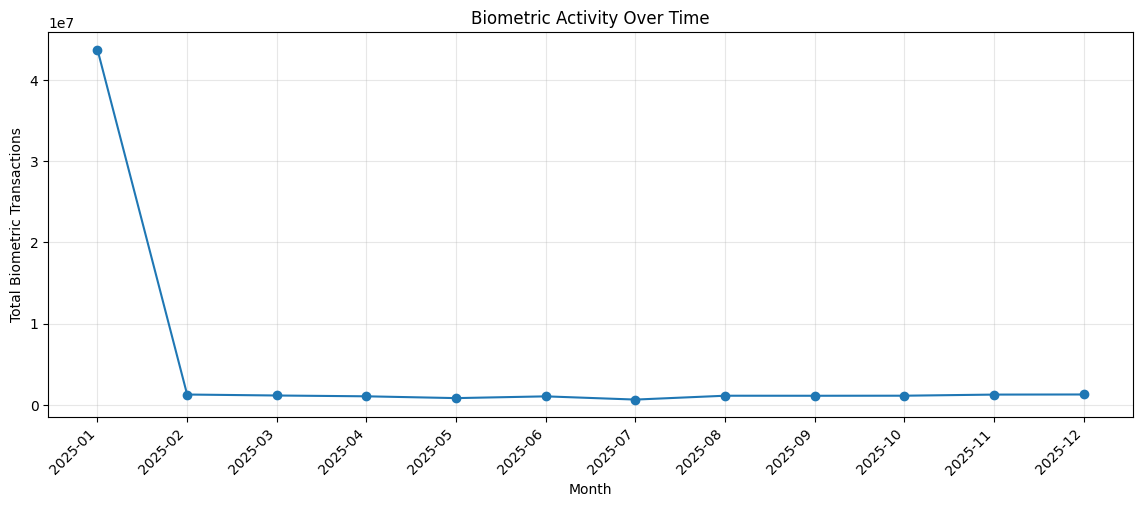

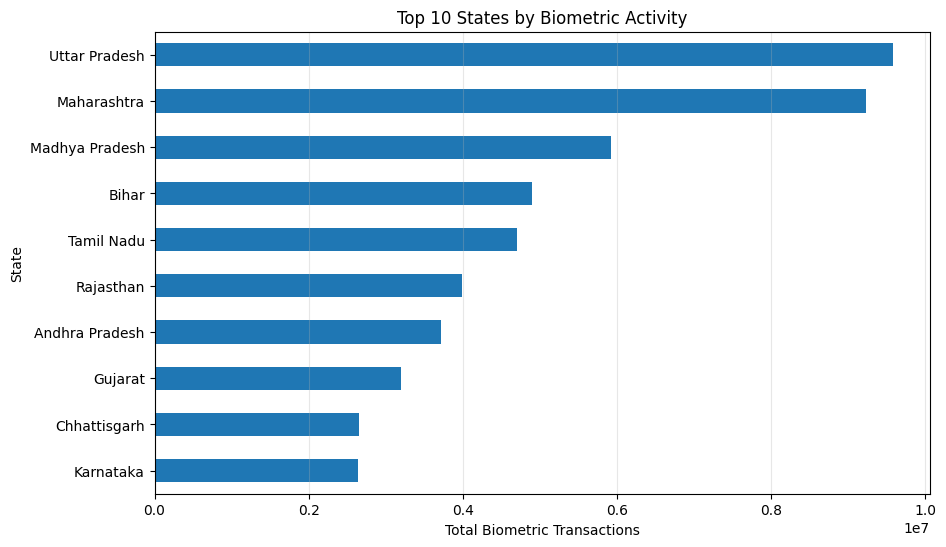

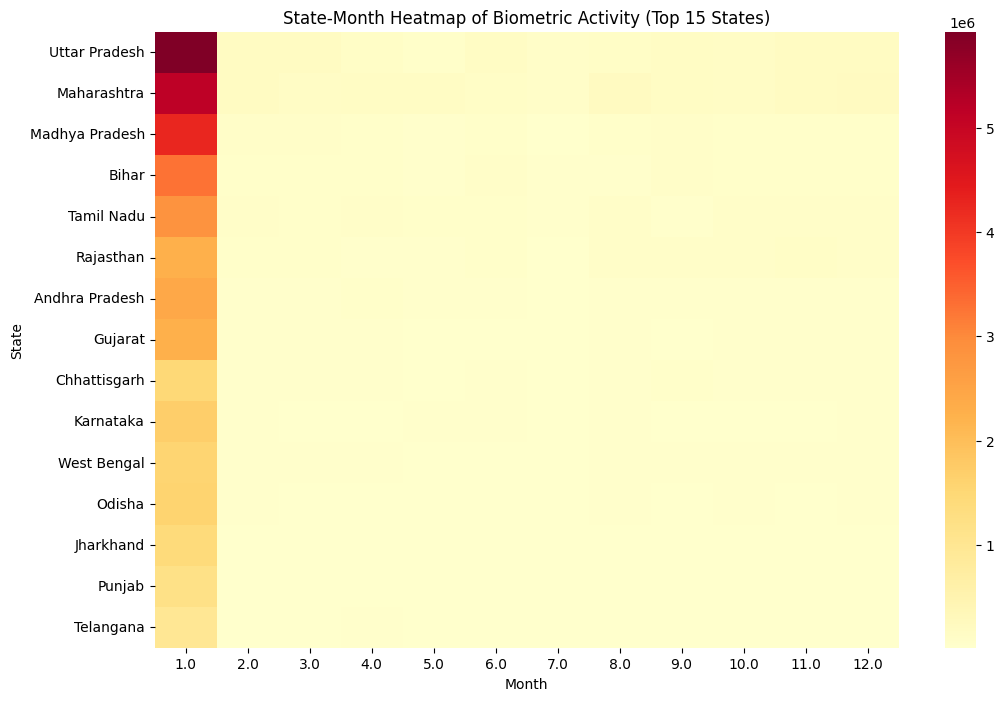

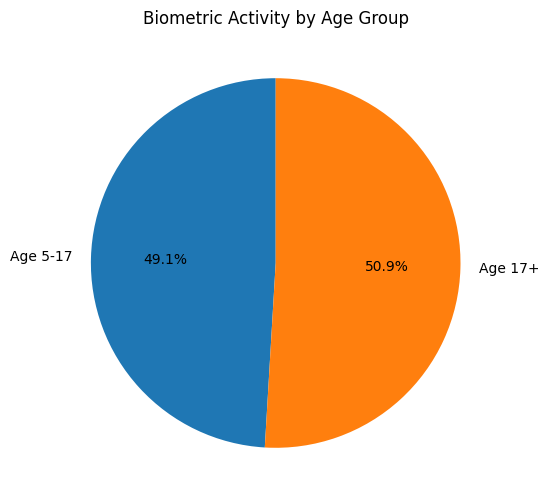

In [124]:
# Biometric analysis prep
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

_df = df.copy()
_df['date_parsed'] = pd.to_datetime(_df['date'], errors='coerce')
_df['year_month'] = _df['date_parsed'].dt.to_period('M')
_df['month'] = _df['date_parsed'].dt.month
_df['total_biometric'] = _df['bio_age_5_17'].fillna(0) + _df['bio_age_17_'].fillna(0)

# Aggregations
monthly_bio = _df.groupby('year_month')['total_biometric'].sum().reset_index()
monthly_bio['year_month_str'] = monthly_bio['year_month'].astype(str)
state_bio = _df.groupby('state_clean')['total_biometric'].sum().sort_values(ascending=False)
heatmap_bio = _df.pivot_table(index='state_clean', columns='month', values='total_biometric', aggfunc='sum').fillna(0)

# 1) Line chart: Monthly trend
plt.figure(figsize=(14, 5))
plt.plot(monthly_bio['year_month_str'], monthly_bio['total_biometric'], marker='o')
plt.title('Biometric Activity Over Time')
plt.xlabel('Month')
plt.ylabel('Total Biometric Transactions')
plt.xticks(rotation=45, ha='right')
plt.grid(alpha=0.3)
plt.show()

# 2) Bar chart: Top 10 states
plt.figure(figsize=(10, 6))
state_bio.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 States by Biometric Activity')
plt.xlabel('Total Biometric Transactions')
plt.ylabel('State')
plt.grid(axis='x', alpha=0.3)
plt.show()

# 3) Heatmap: State vs Month
plt.figure(figsize=(12, 8))
_top_states = state_bio.head(15).index
sns.heatmap(heatmap_bio.loc[_top_states], cmap='YlOrRd')
plt.title('State-Month Heatmap of Biometric Activity (Top 15 States)')
plt.xlabel('Month')
plt.ylabel('State')
plt.show()

# 4) Pie chart: Age-group share
plt.figure(figsize=(6, 6))
plt.pie([_df['bio_age_5_17'].sum(), _df['bio_age_17_'].sum()], labels=['Age 5-17', 'Age 17+'], autopct='%1.1f%%', startangle=90)
plt.title('Biometric Activity by Age Group')
plt.show()